# DeepLense Common Test I: baseline classifier (ResNet-18)

**Goal:** classify lensing images into *no substructure / subhalo (CDM) / vortex*. Report ROC curves and AUC.

**Why this baseline.** ResNet-18 is a small, well-understood CNN (11 M parameters) and the usual first model for this test. I start
from ImageNet weights, because pretrained filters (edges, curves) speed up learning even on astronomy images, and turn the first
convolution into a 1-channel layer by summing its RGB weights. That is exactly what the pretrained network would compute if the grey
image were copied into all three colour channels.

**Protocol (fixed in notebook 01, `split.json`):**
- train = 27,000 images (90 % of `train/`): the model learns from these;
- valid = 3,000 images (10 % of `train/`): picks the best epoch and the inference setting;
- test = 7,500 images (the provided `val/` folder): evaluated **once**, at the end, with everything already fixed.

**Training choices.**
- Inputs are standardised with the train-part mean/std.
- Augmentation uses only the 8 flips/rotations of the square image (the "dihedral group"). They don't change the physics, because a
  lens has no preferred orientation.
- AdamW with a short warm-up, then a cosine learning-rate decay.
- bfloat16 mixed precision (faster, less GPU memory).
- The best epoch is chosen by validation macro AUC.

In [1]:
import json, time, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from sklearn.metrics import roc_auc_score, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42
ROOT = Path("~/gsoc/eval-tests/ml4sci-deeplense").expanduser()
PROC, FIG, WEIGHTS, RUNS = ROOT / "data/processed/common", ROOT / "report/figures", ROOT / "weights", ROOT / "runs"
for d in (FIG, WEIGHTS, RUNS):
    d.mkdir(parents=True, exist_ok=True)

torch.manual_seed(SEED); np.random.seed(SEED)
torch.backends.cudnn.benchmark = True        # faster convolutions; results can differ in the last decimals between runs
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", device,
      torch.cuda.get_device_name(0) if device.type == "cuda" else "")
if device.type == "cuda":
    free, total = torch.cuda.mem_get_info()
    print(f"GPU memory free: {free / 2**30:.1f} of {total / 2**30:.1f} GiB (the GPU is shared with other jobs)")

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | device: cuda NVIDIA RTX 2000 Ada Generation
GPU memory free: 5.8 of 15.6 GiB (the GPU is shared with other jobs)


## 1. Load the data and the fixed split

In [2]:
meta = json.loads((PROC / "split.json").read_text())
CLASSES, NAMES = meta["classes"], meta["class_names"]
X_all  = np.load(PROC / "trainfull_X.npy")            # (30000, 1, 150, 150) float32
y_all  = np.load(PROC / "trainfull_y.npy")
X_test = np.load(PROC / "test_X.npy")                 # (7500, 1, 150, 150) = provided val/ folder
y_test = np.load(PROC / "test_y.npy")
idx_train, idx_valid = np.array(meta["train_idx"]), np.array(meta["valid_idx"])
idx_test = np.arange(len(y_test))
MEAN, STD = meta["pixel_mean_trainfull"], meta["pixel_std_trainfull"]   # computed on the 90 % train part only

assert len(np.intersect1d(idx_train, idx_valid)) == 0
print(f"train {len(idx_train)} | valid {len(idx_valid)} | test {len(idx_test)} | normalise with mean {MEAN:.5f}, std {STD:.5f}")
print("class counts  train:", np.bincount(y_all[idx_train]), " valid:", np.bincount(y_all[idx_valid]), " test:", np.bincount(y_test))

train 27000 | valid 3000 | test 7500 | normalise with mean 0.06169, std 0.11730
class counts  train: [9000 9000 9000]  valid: [1000 1000 1000]  test: [2500 2500 2500]


## 2. Batches and augmentation
Batches are cut straight from the in-memory array and moved to the GPU. Augmentation runs on the GPU: every image gets one of the
8 dihedral transforms (4 rotations × optional mirror), drawn at random.

In [3]:
def batches(X, y, idx, batch_size, shuffle=False, gen=None):
    # Yield standardised (x, y) GPU batches for the rows `idx` of X.
    order = idx[torch.randperm(len(idx), generator=gen).numpy()] if shuffle else idx
    for s in range(0, len(order), batch_size):
        b = order[s:s + batch_size]
        xb = torch.from_numpy(X[b]).to(device, non_blocking=True)
        yb = torch.from_numpy(y[b]).to(device) if y is not None else None
        yield (xb - MEAN) / STD, yb

def dihedral(x, k):
    # k = 0..7: rotate by 90*(k % 4) degrees, mirrored first if k >= 4.
    if k >= 4:
        x = x.flip(-1)
    return torch.rot90(x, k % 4, dims=(-2, -1))

def augment(x):
    ks = torch.randint(0, 8, (x.shape[0],), device=x.device)
    out = torch.empty_like(x)
    for k in range(8):
        m = ks == k
        if m.any():
            out[m] = dihedral(x[m], k)
    return out

# sanity check: the 8 transforms are all different and each one keeps the pixel values
img = torch.from_numpy(X_all[:1]).to(device)
views = [dihedral(img, k) for k in range(8)]
assert all(v.shape == img.shape and torch.allclose(v.sum(), img.sum()) for v in views)
assert len({v.cpu().numpy().tobytes() for v in views}) == 8
print("augmentation OK: 8 distinct, value-preserving views")

augmentation OK: 8 distinct, value-preserving views


## 3. Model

In [4]:
def make_resnet18(n_classes=3):
    m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
    rgb = m.conv1.weight.data                                     # (64, 3, 7, 7)
    m.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
    m.conv1.weight.data.copy_(rgb.sum(dim=1, keepdim=True))       # grey image = same value in R, G and B
    m.fc = nn.Linear(m.fc.in_features, n_classes)
    return m

model = make_resnet18().to(device).to(memory_format=torch.channels_last)
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M")
with torch.no_grad():
    print("output shape for 2 images:", tuple(model(torch.zeros(2, 1, 150, 150, device=device)).shape))

parameters: 11.17 M


output shape for 2 images: (2, 3)


## 4. Training
- **Loss:** cross-entropy.
- **Optimiser:** AdamW, peak learning rate 1e-3, weight decay 0.05, 2 epochs of linear warm-up, then cosine decay to 0 over 30 epochs.
- **Model selection:** after every epoch I compute the validation macro AUC and keep the weights of the best epoch.

In [5]:
CFG = dict(epochs=30, batch_size=128, lr=1e-3, weight_decay=0.05, warmup_epochs=2, seed=SEED)

@torch.no_grad()
def predict(model, X, idx, tta=False, batch_size=256):
    # Softmax probabilities for rows idx of X; with tta=True, averaged over the 8 dihedral views.
    model.eval()
    out = []
    for xb, _ in batches(X, None, idx, batch_size):
        xb = xb.contiguous(memory_format=torch.channels_last)
        with torch.autocast(device.type, dtype=torch.bfloat16):
            views = range(8) if tta else [0]
            p = sum(F.softmax(model(dihedral(xb, k)).float(), dim=1) for k in views) / len(views)
        out.append(p.cpu())
    return torch.cat(out).numpy()

def macro_auc(y, p):
    return roc_auc_score(y, p, multi_class="ovr", average="macro")

def train(model, cfg):
    gen = torch.Generator().manual_seed(cfg["seed"])
    steps_per_epoch = int(np.ceil(len(idx_train) / cfg["batch_size"]))
    total, warm = cfg["epochs"] * steps_per_epoch, cfg["warmup_epochs"] * steps_per_epoch
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    def lr_factor(s):                       # linear warm-up, then cosine decay to 0 at the last step
        if s < warm:
            return (s + 1) / warm
        return 0.5 * (1 + np.cos(np.pi * min(1.0, (s - warm) / max(1, total - warm))))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)
    history, best = [], {"auc": -1.0}
    for epoch in range(1, cfg["epochs"] + 1):
        model.train(); t0 = time.time(); losses = []
        for xb, yb in batches(X_all, y_all, idx_train, cfg["batch_size"], shuffle=True, gen=gen):
            xb = augment(xb).contiguous(memory_format=torch.channels_last)
            with torch.autocast(device.type, dtype=torch.bfloat16):
                loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step(); sched.step()
            losses.append(loss.item())
        p_val = predict(model, X_all, idx_valid)
        y_val = y_all[idx_valid]
        row = dict(epoch=epoch, train_loss=np.mean(losses),
                   valid_loss=F.nll_loss(torch.log(torch.from_numpy(p_val).clamp_min(1e-8)), torch.from_numpy(y_val)).item(),
                   valid_acc=(p_val.argmax(1) == y_val).mean(), valid_auc=macro_auc(y_val, p_val),
                   lr=opt.param_groups[0]["lr"], sec=time.time() - t0)
        history.append(row)
        if row["valid_auc"] > best["auc"]:
            best = {"auc": row["valid_auc"], "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
        print(f"epoch {epoch:2d} | train loss {row['train_loss']:.4f} | valid loss {row['valid_loss']:.4f} "
              f"acc {row['valid_acc']:.4f} AUC {row['valid_auc']:.4f} | {row['sec']:.0f}s")
    return pd.DataFrame(history), best

t_start = time.time()
history, best = train(model, CFG)
print(f"\ntotal training time {(time.time() - t_start) / 60:.1f} min | best valid AUC {best['auc']:.4f} at epoch {best['epoch']}")
torch.save({"state_dict": best["state"], "cfg": CFG, "epoch": best["epoch"], "valid_auc": best["auc"], "mean": MEAN, "std": STD},
           WEIGHTS / "resnet18_baseline_best.pt")
history.to_csv(RUNS / "resnet18_baseline_history.csv", index=False)

epoch  1 | train loss 1.0083 | valid loss 0.7911 acc 0.6373 AUC 0.8312 | 35s


epoch  2 | train loss 0.5807 | valid loss 0.9248 acc 0.6700 AUC 0.8837 | 25s


epoch  3 | train loss 0.4436 | valid loss 0.5183 acc 0.8107 AUC 0.9403 | 25s


epoch  4 | train loss 0.3639 | valid loss 0.3691 acc 0.8647 AUC 0.9627 | 25s


epoch  5 | train loss 0.3266 | valid loss 0.3013 acc 0.8903 AUC 0.9716 | 25s


epoch  6 | train loss 0.2875 | valid loss 0.2790 acc 0.8950 AUC 0.9761 | 25s


... (20 outputs left out)

epoch 27 | train loss 0.0734 | valid loss 0.1184 acc 0.9617 AUC 0.9948 | 25s


epoch 28 | train loss 0.0689 | valid loss 0.1182 acc 0.9600 AUC 0.9949 | 25s


epoch 29 | train loss 0.0663 | valid loss 0.1158 acc 0.9617 AUC 0.9951 | 25s


epoch 30 | train loss 0.0657 | valid loss 0.1160 acc 0.9620 AUC 0.9950 | 25s

total training time 12.6 min | best valid AUC 0.9951 at epoch 29


## 5. Learning curves

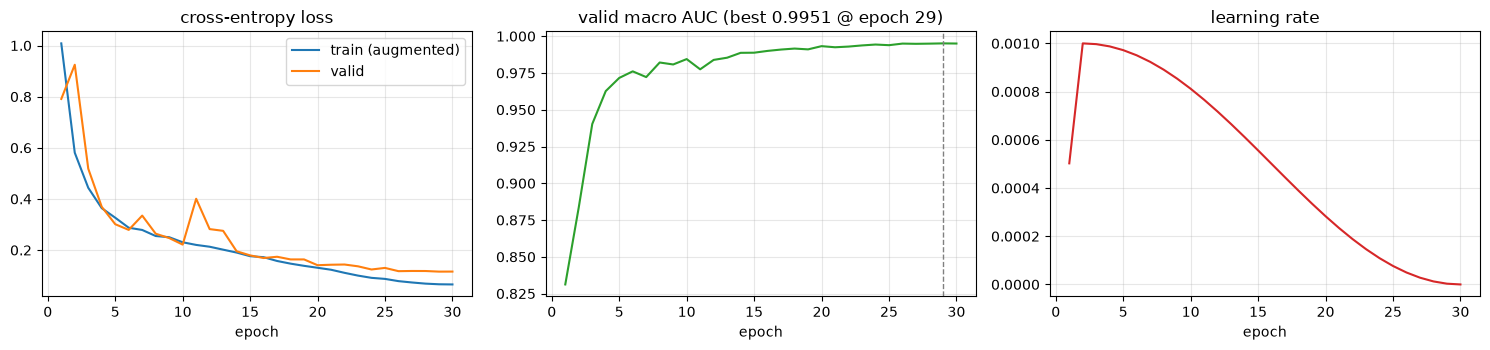

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(history.epoch, history.train_loss, label="train (augmented)"); axes[0].plot(history.epoch, history.valid_loss, label="valid")
axes[0].set_title("cross-entropy loss"); axes[0].legend()
axes[1].plot(history.epoch, history.valid_auc, color="C2"); axes[1].axvline(best["epoch"], ls="--", c="grey", lw=1)
axes[1].set_title(f"valid macro AUC (best {best['auc']:.4f} @ epoch {best['epoch']})")
axes[2].plot(history.epoch, history.lr, color="C3"); axes[2].set_title("learning rate")
for ax in axes: ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / "02_learning_curves.png", bbox_inches="tight"); plt.show()

## 6. Choose the inference setting on the validation set
Test-time augmentation (TTA) averages the predictions over the 8 dihedral views of each image. Whether to use it is decided here, on
**valid**, before the test set is touched.

In [7]:
model.load_state_dict(best["state"])
y_val = y_all[idx_valid]
p_val_plain, p_val_tta = predict(model, X_all, idx_valid), predict(model, X_all, idx_valid, tta=True)
auc_plain, auc_tta = macro_auc(y_val, p_val_plain), macro_auc(y_val, p_val_tta)
USE_TTA = auc_tta > auc_plain
print(f"valid macro AUC  without TTA {auc_plain:.4f} | with 8-view TTA {auc_tta:.4f}  ->  use TTA: {USE_TTA}")

valid macro AUC  without TTA 0.9951 | with 8-view TTA 0.9967  ->  use TTA: True


## 7. Final evaluation on the held-out test set (run once)

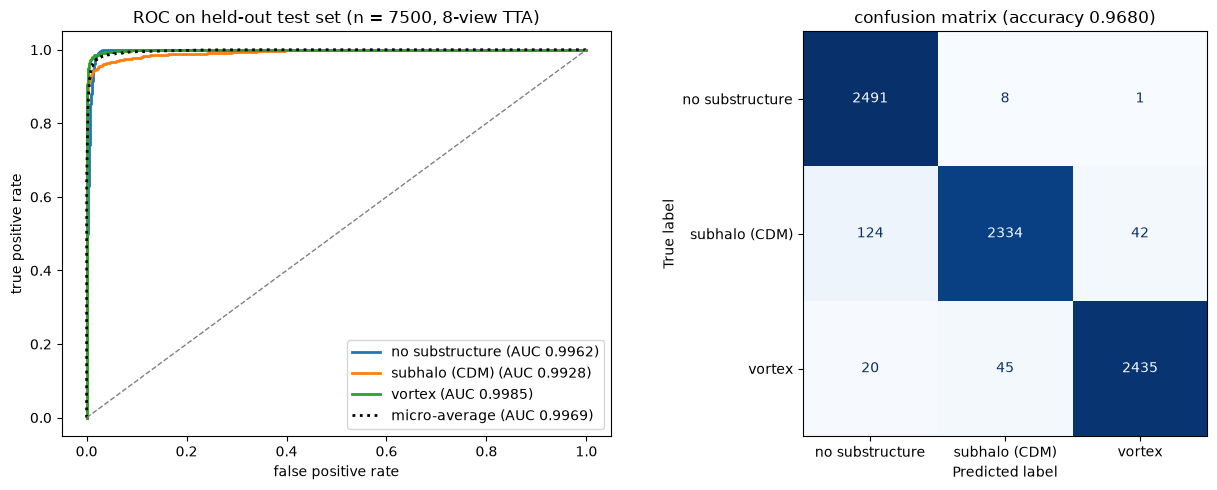

,AUC
curve,
no substructure vs rest,0.9962
subhalo (CDM) vs rest,0.9928
vortex vs rest,0.9985
micro-average,0.9969
macro-average (one-vs-rest),0.9958


                 precision    recall  f1-score   support

no substructure     0.9454    0.9964    0.9702      2500
  subhalo (CDM)     0.9778    0.9336    0.9552      2500
         vortex     0.9826    0.9740    0.9783      2500

       accuracy                         0.9680      7500
      macro avg     0.9686    0.9680    0.9679      7500
   weighted avg     0.9686    0.9680    0.9679      7500



In [8]:
p_test = predict(model, X_test, idx_test, tta=USE_TTA)
pred = p_test.argmax(1)

rows = []
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
for i, cls in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(y_test == i, p_test[:, i])
    a = auc(fpr, tpr); rows.append({"curve": f"{NAMES[cls]} vs rest", "AUC": a})
    ax.plot(fpr, tpr, lw=2, label=f"{NAMES[cls]} (AUC {a:.4f})")
y_onehot = np.eye(3)[y_test]
fpr_mi, tpr_mi, _ = roc_curve(y_onehot.ravel(), p_test.ravel())
rows.append({"curve": "micro-average", "AUC": auc(fpr_mi, tpr_mi)})
rows.append({"curve": "macro-average (one-vs-rest)", "AUC": macro_auc(y_test, p_test)})
ax.plot(fpr_mi, tpr_mi, ls=":", c="k", lw=2, label=f"micro-average (AUC {rows[-2]['AUC']:.4f})")
ax.plot([0, 1], [0, 1], c="grey", lw=1, ls="--")
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title(f"ROC on held-out test set (n = {len(y_test)}{', 8-view TTA' if USE_TTA else ''})"); ax.legend(loc="lower right")

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=[NAMES[c] for c in CLASSES]).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title(f"confusion matrix (accuracy {(pred == y_test).mean():.4f})")
fig.tight_layout(); fig.savefig(FIG / "02_roc_confusion_test.png", bbox_inches="tight"); plt.show()

auc_table = pd.DataFrame(rows).set_index("curve").round(4)
display(auc_table)
print(classification_report(y_test, pred, target_names=[NAMES[c] for c in CLASSES], digits=4))

results = {"model": "ResNet-18 (ImageNet init, 1-channel conv1)", "cfg": CFG, "best_epoch": best["epoch"],
           "valid_macro_auc": best["auc"], "tta": bool(USE_TTA),
           "test": {**auc_table["AUC"].to_dict(), "accuracy": float((pred == y_test).mean())}}
_ = (ROOT / "report/results_02_resnet18.json").write_text(json.dumps(results, indent=2))

## 8. Notes

**Result (held-out test set, 7,500 images, best epoch 29, 8-view TTA):**

| | AUC |
|---|---|
| no substructure vs rest | 0.9962 |
| subhalo (CDM) vs rest | 0.9928 |
| vortex vs rest | 0.9985 |
| micro-average | 0.9969 |
| **macro-average** | **0.9958** |

Accuracy is 96.8 %. On the validation set, TTA raised macro AUC from 0.9951 to 0.9967, so it was switched on before the test set was
used.

**What the numbers say:**
- **Most mistakes are subhalos predicted as "no substructure"** (124 of 2,500 subhalo images). That fits notebook 01: the subhalo
  signal is the faintest (smallest difference from the smooth lens), while vortex structure is easier to detect.
- **"No substructure" has 99.6 % recall but 94.5 % precision.** When the model is unsure, it falls back to "smooth lens".
- **Little overfitting.** Validation loss follows training loss (0.116 vs 0.066 at the end; the training loss is on augmented images).
  The two spikes (epochs 2 and 11) happen while the learning rate is high, and they disappear as it decays.
- **Validation AUC was still creeping up at epoch 30,** so a longer schedule may add a little.

**Honesty notes:**
- Before this run, the notebook was executed once with 1 epoch, only to check that every cell runs end to end. No setting was changed
  because of that run.
- `cudnn.benchmark` makes reruns differ slightly, in the 3rd–4th decimal.

**Next ideas (in order):**
1. Keep more spatial detail early, aimed at the faint subhalo signal: ResNet-18 with a 3×3 stride-1 first conv and no max-pool.
2. Train longer (50 epochs).
3. Compare a second architecture (EfficientNet-B0 or a small ViT) and average the two models' probabilities.